In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# ---- 设备:优先用 5070 Ti ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch 版本:", torch.__version__)
print("CUDA 可用:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("显卡:", torch.cuda.get_device_name(0))
    print("计算能力 (sm):", torch.cuda.get_device_capability(0))  # 5070Ti 应为 (12, 0)

# 让 Blackwell 上的 matmul 走 TF32,加速训练(精度影响可忽略)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

PyTorch 版本: 2.11.0+cu128
CUDA 可用: True
显卡: NVIDIA GeForce RTX 5070 Ti
计算能力 (sm): (12, 0)


In [2]:
# VAE 是自监督:输入 x,目标也是重建 x,不需要标签。
# MNIST 像素被归一化到 [0,1],这样才能配合【伯努利解码器 + BCE 损失】。
transform = transforms.ToTensor()  # -> [0,1], shape (1,28,28)

train_set = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

BATCH = 256
# num_workers 和 pin_memory 帮助喂满 GPU
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH, shuffle=False,
                          num_workers=4, pin_memory=True)

# 看一眼数据形状
x0, _ = next(iter(train_loader))
print("一个 batch:", x0.shape)  # (256, 1, 28, 28)

一个 batch: torch.Size([256, 1, 28, 28])


In [3]:
LATENT_DIM = 20  # 隐空间维度 z

class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim

        # ---------- 编码器主干 ----------
        self.enc = nn.Sequential(
            nn.Flatten(),              # (B,1,28,28) -> (B,784)
            nn.Linear(784, 400),
            nn.ReLU(),
        )
        # (A) 编码器【不直接输出 z】,而是输出分布 q_φ(z|x)=N(μ,σ²) 的两组参数。
        #     注意这里输出的是 logσ²(log-variance)而非 σ,原因见下方说明。
        self.fc_mu     = nn.Linear(400, latent_dim)   # μ(x)
        self.fc_logvar = nn.Linear(400, latent_dim)   # log σ²(x)

        # ---------- 解码器 ----------
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 784),
            # 不加 Sigmoid,后面用 BCE_with_logits 更数值稳定;可视化时再手动 sigmoid
        )

    # ---- 编码:x -> 分布参数 (μ, logσ²) ----
    def encode(self, x):
        h = self.enc(x)
        mu     = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar   # 这两个向量【定义了】一个高斯分布,还没采样

    # ---- (B) 重参数化技巧:把"带参数的采样"改写成"无参数噪声 + 可导变换" ----
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)      # σ = exp(0.5·logσ²)
        eps = torch.randn_like(std)        # ε ~ N(0, I),随机性【全在这里】,与参数无关
        z = mu + std * eps                 # z = μ + σ⊙ε  ← 这一步可导,梯度能回传到 μ、logvar
        return z
        # 若没有这一步而直接 z ~ N(μ,σ²),采样节点不可导,encoder 无法训练。

    # ---- (C) 解码:z -> 伯努利分布参数(每个像素为 1 的概率的 logit) ----
    def decode(self, z):
        logits = self.dec(z)               # 784 个 logit
        return logits                      # p_θ(x|z) = Bernoulli(sigmoid(logits))

    # ---- 完整前向:走一遍数据流 ----
    def forward(self, x):
        mu, logvar = self.encode(x)             # 步骤1:x -> 分布参数
        z = self.reparameterize(mu, logvar)     # 步骤2:采样一个 z(即 L=1 的 Monte Carlo 样本)
        logits = self.decode(z)                 # 步骤3:z -> 重建分布
        return logits, mu, logvar

model = VAE().to(device)
print(model)

VAE(
  (enc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=400, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=20, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=784, bias=True)
  )
)


In [4]:
def vae_loss(logits, x, mu, logvar):
    B = x.size(0)
    x_flat = x.view(B, -1)  # (B,784),真实像素 ∈ [0,1]

    # ---- 重建项:-E_{q_φ(z|x)}[ ln p_θ(x|z) ] ----
    # decoder 假设为【伯努利分布】,故 -ln p = 二元交叉熵(BCE)。
    # 这里用的 z 是上一步【采样出的那一个】,所以这就是对期望的
    # 【Monte Carlo 估计,L=1】:用单个样本代替整个期望积分。
    # reduction='sum' 后再除以 batch,得到每张图的平均。
    recon = F.binary_cross_entropy_with_logits(logits, x_flat, reduction='sum') / B

    # ---- KL 项:KL( N(μ,σ²) || N(0,I) ) ----
    # 两个高斯的 KL 有【闭式解】,无需采样,直接代入 μ、logσ²:
    #   KL = 0.5 * Σ ( μ² + σ² - logσ² - 1 )
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B

    # ELBO 的负值(我们最小化它),recon + kld 即 -ELBO
    return recon + kld, recon, kld

In [5]:
from torch import optim

EPOCHS = 20
model = VAE().to(device)
opt = optim.Adam(model.parameters(), lr=1e-3)

history = {"loss": [], "recon": [], "kld": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = np.zeros(3)  # loss, recon, kld
    for x, _ in train_loader:
        x = x.to(device, non_blocking=True)

        # ---- 一次完整数据流 ----
        logits, mu, logvar = model(x)               # encode -> 重参数化采样 -> decode
        loss, recon, kld = vae_loss(logits, x, mu, logvar)

        # ---- 反向传播:梯度经【重参数化的可导路径】回传到 encoder ----
        opt.zero_grad()
        loss.backward()
        opt.step()

        running += np.array([loss.item(), recon.item(), kld.item()])

    running /= len(train_loader)
    history["loss"].append(running[0])
    history["recon"].append(running[1])
    history["kld"].append(running[2])
    print(f"Epoch {epoch:2d} | -ELBO {running[0]:7.2f} | "
          f"Recon(BCE) {running[1]:7.2f} | KL {running[2]:6.2f}")

Epoch  1 | -ELBO  189.68 | Recon(BCE)  177.13 | KL  12.56
Epoch  2 | -ELBO  132.51 | Recon(BCE)  112.75 | KL  19.76
Epoch  3 | -ELBO  120.67 | Recon(BCE)   98.21 | KL  22.46
Epoch  4 | -ELBO  115.95 | Recon(BCE)   92.42 | KL  23.53
Epoch  5 | -ELBO  113.25 | Recon(BCE)   89.10 | KL  24.15
Epoch  6 | -ELBO  111.55 | Recon(BCE)   87.05 | KL  24.50
Epoch  7 | -ELBO  110.32 | Recon(BCE)   85.62 | KL  24.70
Epoch  8 | -ELBO  109.41 | Recon(BCE)   84.53 | KL  24.89
Epoch  9 | -ELBO  108.65 | Recon(BCE)   83.69 | KL  24.96
Epoch 10 | -ELBO  108.00 | Recon(BCE)   82.97 | KL  25.03
Epoch 11 | -ELBO  107.53 | Recon(BCE)   82.41 | KL  25.12
Epoch 12 | -ELBO  107.04 | Recon(BCE)   81.89 | KL  25.16
Epoch 13 | -ELBO  106.72 | Recon(BCE)   81.48 | KL  25.24
Epoch 14 | -ELBO  106.38 | Recon(BCE)   81.12 | KL  25.27
Epoch 15 | -ELBO  106.12 | Recon(BCE)   80.79 | KL  25.33
Epoch 16 | -ELBO  105.90 | Recon(BCE)   80.53 | KL  25.37
Epoch 17 | -ELBO  105.63 | Recon(BCE)   80.25 | KL  25.38
Epoch 18 | -EL

C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3303975079.py:16: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3303975079.py:16: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3303975079.py:16: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3303975079.py:16: UserWarning: Glyph 19979 (\N{CJK UNIFIED IDEOGRAPH-4E0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3303975079.py:16: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\J

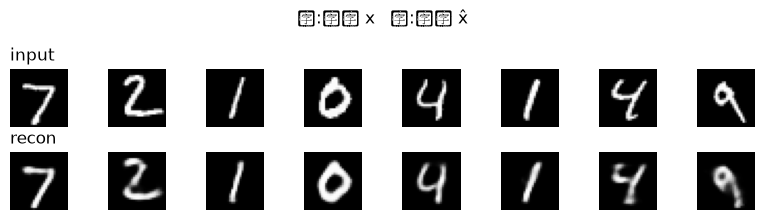

In [6]:
model.eval()
with torch.no_grad():
    x, _ = next(iter(test_loader))
    x = x.to(device)
    logits, _, _ = model(x)
    recon = torch.sigmoid(logits).view(-1, 1, 28, 28)  # 伯努利概率 -> 图像

n = 8
fig, axes = plt.subplots(2, n, figsize=(n, 2.2))
for i in range(n):
    axes[0, i].imshow(x[i, 0].cpu(), cmap="gray");      axes[0, i].axis("off")
    axes[1, i].imshow(recon[i, 0].cpu(), cmap="gray");  axes[1, i].axis("off")
axes[0, 0].set_title("input",  loc="left")
axes[1, 0].set_title("recon",  loc="left")
plt.suptitle("上:原图 x   下:重建 x̂")
plt.tight_layout(); plt.show()

### 从先验采样生成全新图像

C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\2954870707.py:12: UserWarning: Glyph 20174 (\N{CJK UNIFIED IDEOGRAPH-4ECE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\2954870707.py:12: UserWarning: Glyph 20808 (\N{CJK UNIFIED IDEOGRAPH-5148}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\2954870707.py:12: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\2954870707.py:12: UserWarning: Glyph 37319 (\N{CJK UNIFIED IDEOGRAPH-91C7}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\2954870707.py:12: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\J

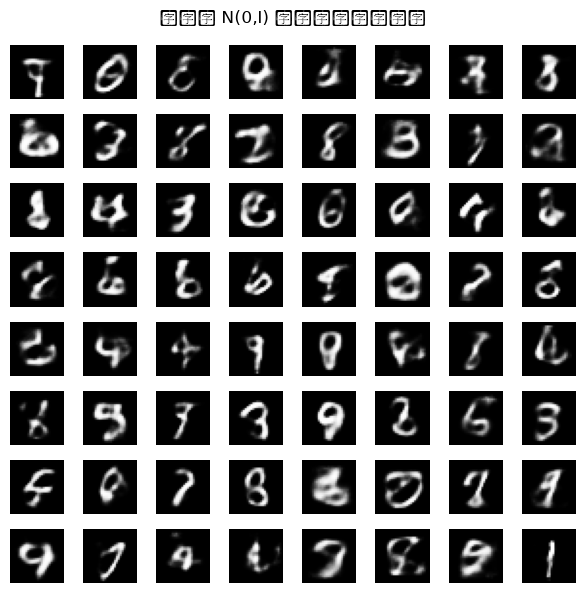

In [7]:
# 训练完可【扔掉 encoder】,直接从先验 p(z)=N(0,I) 采样 z,喂给 decoder 生成新样本。
# 这正是 KL 项把 q_φ 拉向 N(0,I) 换来的能力:隐空间连续、规整、可采样。
model.eval()
with torch.no_grad():
    z = torch.randn(64, LATENT_DIM, device=device)   # 从先验直接采样
    gen = torch.sigmoid(model.decode(z)).view(-1, 1, 28, 28)

fig, axes = plt.subplots(8, 8, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(gen[i, 0].cpu(), cmap="gray"); ax.axis("off")
plt.suptitle("从先验 N(0,I) 采样生成的新数字")
plt.tight_layout(); plt.show()

C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3399357276.py:16: UserWarning: Glyph 38544 (\N{CJK UNIFIED IDEOGRAPH-9690}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3399357276.py:16: UserWarning: Glyph 31354 (\N{CJK UNIFIED IDEOGRAPH-7A7A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3399357276.py:16: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3399357276.py:16: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_19916\3399357276.py:16: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\J

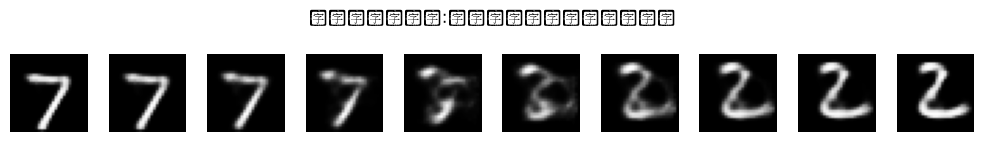

In [8]:
# 取两张图,在隐空间对它们的 μ 做线性插值,看解码结果是否平滑过渡。
model.eval()
with torch.no_grad():
    x, _ = next(iter(test_loader))
    x = x.to(device)
    mu, _ = model.encode(x)
    z1, z2 = mu[0], mu[1]           # 两个端点(用均值,忽略噪声)
    alphas = torch.linspace(0, 1, 10, device=device)
    zs = torch.stack([(1 - a) * z1 + a * z2 for a in alphas])
    interp = torch.sigmoid(model.decode(zs)).view(-1, 1, 28, 28)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for i, ax in enumerate(axes):
    ax.imshow(interp[i, 0].cpu(), cmap="gray"); ax.axis("off")
plt.suptitle("隐空间线性插值:从一个数字平滑变到另一个")
plt.tight_layout(); plt.show()